# 01 — Análise exploratória e divisão dos dados

Classificação de resíduos com o dataset **TrashNet** (`dataset-resized.zip`, 512×384).

Este notebook:
1. baixa e extrai o dataset;
2. verifica quantidade de imagens, dimensões, canais de cor, integridade e arquivos duplicados;
3. mostra exemplos das seis classes e uma mesma imagem nas três resoluções;
4. gera a **divisão estratificada 70/15/15 (semente 42)** usada em todos os experimentos (`splits/split.csv`).

Não precisa de GPU.

In [26]:
# Configuração do ambiente
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Caminho da pasta trashnet-rna no seu Google Drive. Para descobrir: painel "Arquivos"
    # (ícone de pasta à esquerda) -> drive -> MyDrive -> ... -> botão direito na pasta
    # trashnet-rna -> "Copiar caminho", e cole entre as aspas abaixo.
    PROJECT_DIR = "/content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna"
    # As imagens ficam no disco do próprio Colab, que é mais rápido que o Drive.
    os.environ["TRASHNET_DATA_DIR"] = "/content/data"
else:
    PROJECT_DIR = ".."  # rodando no computador, a partir da pasta notebooks/
if not os.path.isdir(os.path.join(PROJECT_DIR, "src", "trashnet")):
    raise FileNotFoundError(f"Não encontrei o projeto em {PROJECT_DIR}. Corrija o PROJECT_DIR acima.")
os.chdir(PROJECT_DIR)
sys.path.insert(0, os.path.join(os.getcwd(), "src"))
print("Projeto:", os.getcwd())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from trashnet import config as C
from trashnet import data as D
from trashnet import evaluate as E

root = D.download_dataset()

Dataset já disponível em /content/data/dataset-resized


## 1. Inventário e integridade dos arquivos

In [28]:
inv = D.build_inventory()
C.INVENTORY_CSV.parent.mkdir(parents=True, exist_ok=True)
inv.to_csv(C.INVENTORY_CSV, index=False)

print("Total de imagens:", len(inv))
print("Arquivos corrompidos/ilegíveis:", (~inv["ok"]).sum())
contagem = inv["label"].value_counts().reindex(C.CLASSES).rename("imagens").to_frame()
contagem["%"] = (100 * contagem["imagens"] / contagem["imagens"].sum()).round(1)
contagem

Total de imagens: 2527
Arquivos corrompidos/ilegíveis: 0


,imagens,%
label,,
glass,501,19.8
paper,594,23.5
cardboard,403,15.9
plastic,482,19.1
metal,410,16.2
trash,137,5.4


In [39]:
print("Dimensões (largura x altura):")
print(inv.groupby(["width", "height"]).size().rename("imagens").to_string(), "\n")
print("Modo de cor (RGB = 3 canais):")
print(inv["mode"].value_counts().to_string(), "\n")
razao = inv["label"].value_counts().max() / inv["label"].value_counts().min()
print(f"Razão entre a classe mais e a menos frequente: {razao:.2f}")

Dimensões (largura x altura):
width  height
512    384       2527 

Modo de cor (RGB = 3 canais):
mode
RGB    2527 

Razão entre a classe mais e a menos frequente: 4.34


### Arquivos idênticos (mesmo hash MD5)

In [40]:
dups = inv[inv.duplicated(subset=['md5'], keep=False)]
print("Arquivos que têm uma cópia idêntica:", len(dups))
dups

Arquivos que têm uma cópia idêntica: 6


,filepath,label,width,height,mode,format,exif_orientation,ok,error,md5,label_idx
18,glass/glass115.jpg,glass,512,384,RGB,JPEG,1,True,,70df08c3ce6d55e25df4edbbe45e5fe3,0
85,glass/glass176.jpg,glass,512,384,RGB,JPEG,1,True,,a2236bc6f8eae80bf7d6c5f259df8760,0
321,glass/glass389.jpg,glass,512,384,RGB,JPEG,1,True,,e52ec9a8f6089b5780728b148c9f795e,0
1557,plastic/plastic152.jpg,plastic,512,384,RGB,JPEG,1,True,,a2236bc6f8eae80bf7d6c5f259df8760,3
1757,plastic/plastic332.jpg,plastic,512,384,RGB,JPEG,1,True,,e52ec9a8f6089b5780728b148c9f795e,3
2381,metal/metal91.jpg,metal,512,384,RGB,JPEG,1,True,,70df08c3ce6d55e25df4edbbe45e5fe3,4


Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_duplicatas.png


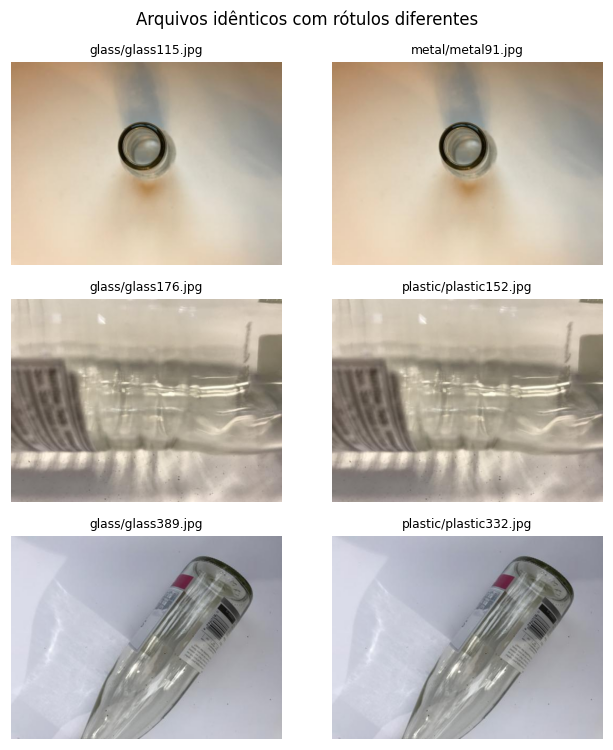

In [41]:
# Mostra cada grupo de arquivos idênticos lado a lado
grupos = list(dups.groupby("md5"))
if grupos:
    fig, axes = plt.subplots(len(grupos), 2, figsize=(6, 2.3 * len(grupos)), squeeze=False)
    for r, (_, g) in enumerate(grupos):
        for k, f in enumerate(g["filepath"][:2]):
            axes[r, k].imshow(plt.imread(C.DATASET_ROOT / f))
            axes[r, k].set_title(f, fontsize=8); axes[r, k].axis("off")
    fig.suptitle("Arquivos idênticos com rótulos diferentes")
    fig.tight_layout(); E.save_fig(fig, "fig_duplicatas"); plt.show()

**Tratamento:** os arquivos listados em `ARQUIVOS_EXCLUIDOS` (`src/trashnet/config.py`) são removidos antes da divisão.
A escolha inicial foi remover as duas cópias de cada par, porque não dá para saber qual rótulo está certo.

> ✍️ **Equipe:** confirmem ou alterem essa decisão (ver `DECISOES_DA_EQUIPE.md`) e justifiquem no artigo.

## 2. Exemplos e características visuais

Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_exemplos_classes.png


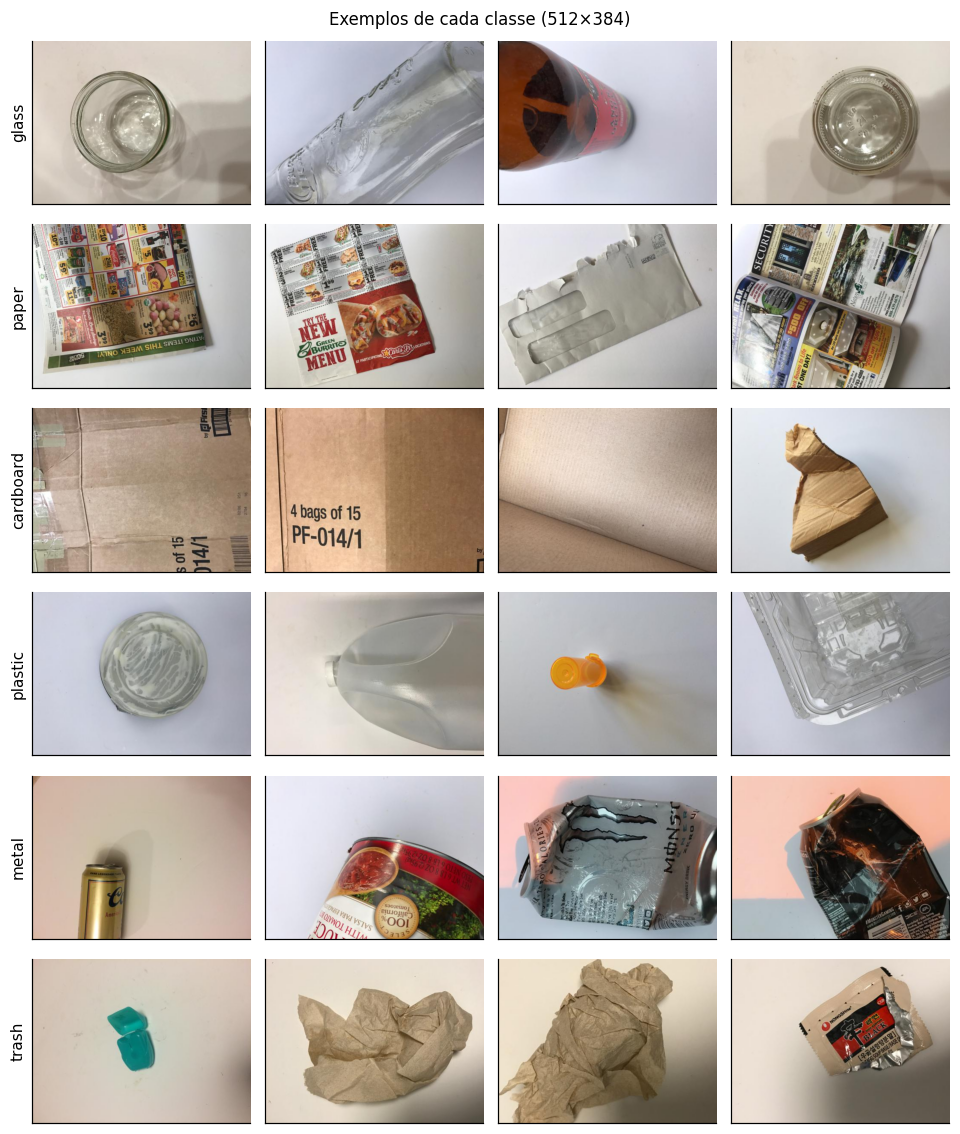

In [42]:
fig = E.plot_examples(inv[inv["ok"]], n_per_class=4)
E.save_fig(fig, "fig_exemplos_classes"); plt.show()

In [43]:
# Estatísticas simples de cor por classe (em 128x96 para ser rápido)
rows = []
for c in C.CLASSES:
    files = inv.loc[(inv["label"] == c) & inv["ok"], "filepath"]
    X = np.stack([D.load_image(C.DATASET_ROOT / f, (128, 96)) for f in files]).astype(np.float32)
    rows.append({"classe": c, "R": X[..., 0].mean(), "G": X[..., 1].mean(), "B": X[..., 2].mean(),
                 "brilho_medio": X.mean(), "desvio_brilho": X.mean(axis=(1, 2, 3)).std()})
cores = pd.DataFrame(rows).round(1)
cores

,classe,R,G,B,brilho_medio,desvio_brilho
0,glass,176.399994,170.500000,163.100006,170.000000,14.8
1,paper,172.199997,164.600006,155.500000,164.100006,19.5
2,cardboard,170.100006,148.899994,128.000000,149.000000,21.9
3,plastic,171.100006,170.100006,169.000000,170.100006,14.8
4,metal,164.800003,157.000000,151.899994,157.899994,25.5
5,trash,178.800003,166.100006,149.100006,164.699997,17.4


Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_resolucoes.png


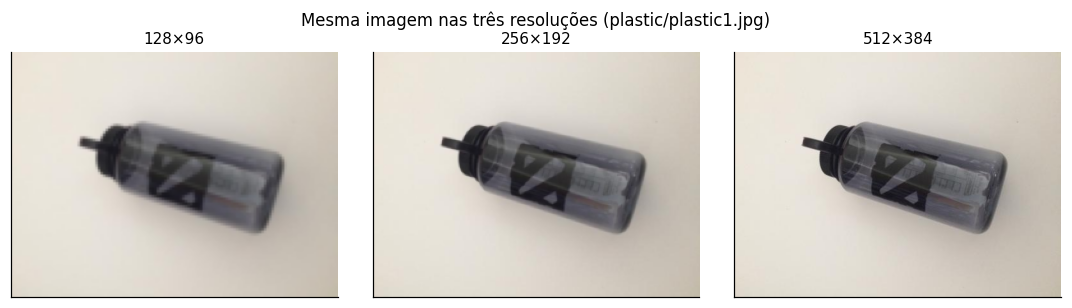

In [34]:
exemplo = inv.loc[inv["label"] == "plastic", "filepath"].iloc[0]
fig = E.plot_same_image_resolutions(exemplo)
E.save_fig(fig, "fig_resolucoes"); plt.show()

> ✍️ **Equipe — características que dificultam a classificação:** descrevam aqui o que observaram nos exemplos
> (ex.: fundo branco/uniforme em quase todas as fotos, iluminação e reflexos, objetos transparentes de vidro e plástico,
> papel × papelão com texturas parecidas, classe *trash* muito heterogênea e com poucas amostras etc.).

## 3. Divisão estratificada 70% / 15% / 15% (semente 42)

In [44]:
split_df = D.make_split(inv)
if C.SPLIT_CSV.exists():
    salvo = D.load_split()
    igual = salvo["filepath"].equals(split_df["filepath"]) and salvo["split"].equals(split_df["split"])
    print("A divisão gerada agora é igual à salva em splits/split.csv:", igual)
    if not igual:
        print("ATENÇÃO: os treinos usam o arquivo salvo. Apaguem splits/split.csv para gerar um novo.")
else:
    D.save_split(split_df)
D.split_summary(split_df)

Política de duplicatas: remove_conflicts | removidas por conflito de rótulo: 6
A divisão gerada agora é igual à salva em splits/split.csv: False
ATENÇÃO: os treinos usam o arquivo salvo. Apaguem splits/split.csv para gerar um novo.


split,train,val,test,total
label,,,,
glass,348,75,75,498
paper,416,89,89,594
cardboard,282,60,61,403
plastic,336,72,72,480
metal,286,61,62,409
trash,96,21,20,137
total,1764,378,379,2521


In [36]:
tab = D.split_summary(split_df)
(tab.drop(index="total")[["train", "val", "test"]].div(tab.drop(index="total")["total"], axis=0) * 100).round(1)

split,train,val,test
label,,,
glass,69.9,15.1,15.1
paper,70.0,15.0,15.0
cardboard,70.0,14.9,15.1
plastic,70.0,15.0,15.0
metal,69.9,14.9,15.2
trash,70.1,15.3,14.6


Figura salva: /content/drive/MyDrive/Faculdade/UNIFOR/IA/Redes Neurais/trashnet-rna/figures/fig_distribuicao_classes.png


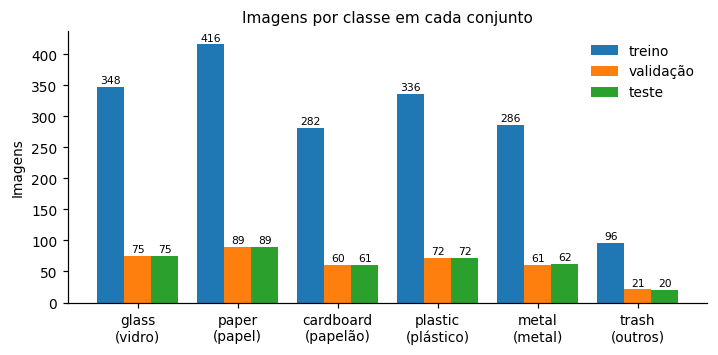

In [37]:
fig = E.plot_class_distribution(split_df)
E.save_fig(fig, "fig_distribuicao_classes"); plt.show()
C.RESULTS_DIR.mkdir(exist_ok=True)
D.split_summary(split_df).to_csv(C.RESULTS_DIR / "tabela_divisao.csv")

### Pesos de classe (calculados somente com o treino)

In [45]:
y_tr = split_df.loc[split_df["split"] == "train", "label_idx"].to_numpy()
cw = D.class_weights_from_train(y_tr)
pd.DataFrame({"classe": C.CLASSES, "imagens_treino": np.bincount(y_tr), "peso": [round(cw[i], 3) for i in range(6)]})

,classe,imagens_treino,peso
0,glass,348,0.845
1,paper,416,0.707
2,cardboard,282,1.043
3,plastic,336,0.875
4,metal,286,1.028
5,trash,96,3.062
